a = 3
Ground state energy = -9.282865342987053
----------------------
a = 5
Ground state energy = -10.841082034369279
----------------------
a = 7
Ground state energy = -11.560191925229613
----------------------


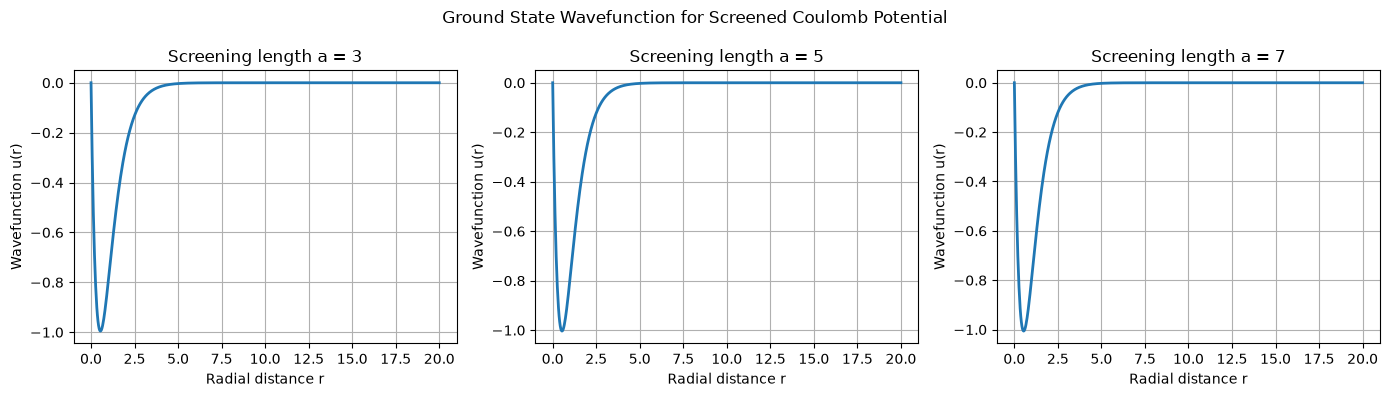

In [1]:

import numpy as np
import matplotlib.pyplot as plt


e = 3.795
hbar_c = 1973.0
mc2 = 0.511 * 10**6

C = hbar_c**2 / (2 * mc2)


ri = 0.001
rf = 20
N = 600


l = 0


a_values = [3, 5, 7]



def potential(r, a):

    V = -(e**2 / r) * np.exp(-r/a)

    return V



def make_matrix(r, dr, a):

    V = potential(r, a)

    
    V = V + C * l * (l+1) / r**2

    main = 2*C/dr**2 + V
    side = -C/dr**2

    H = np.diag(main)
    H = H + np.diag(np.ones(N-1)*side, 1)
    H = H + np.diag(np.ones(N-1)*side, -1)

    return H



def solve(a):

    dr = (rf-ri)/(N+1)

    r = ri + dr*np.arange(1, N+1)

    H = make_matrix(r, dr, a)

    energy, vectors = np.linalg.eigh(H)

    
    u = vectors[:, 0]

    
    u = np.concatenate(([0], u, [0]))

    
    u = u / np.sqrt(np.sum(u**2)*dr)

    full_r = np.concatenate(([ri], r, [rf]))

    return full_r, u, energy[0]



fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i in range(len(a_values)):

    a = a_values[i]

    r, u, E = solve(a)

    axes[i].plot(r, u, linewidth=2)

    axes[i].set_title("Screening length a = " + str(a))

    axes[i].set_xlabel("Radial distance r")
    axes[i].set_ylabel("Wavefunction u(r)")

    axes[i].grid()

    print("a =", a)
    print("Ground state energy =", E)
    print("----------------------")


plt.suptitle("Ground State Wavefunction for Screened Coulomb Potential")

plt.tight_layout()
plt.show()
